<center><h1> ETI195 - Ética para Ciencia de Datos y Estadística </h1><center>
<center><h2> Taller Sumativo II: Sesgos, justicia, y discriminación <h2></center>

# `Instrucciones Generales`


## `Temas formales`

**Modalidad**: Grupos de 3 personas.

**Formato de entrega:** El trabajo debe entregarse a través de Canvas, tanto en formato Jupyter ejecutable (.ipynb) como en formato PDF.

**Formalidades de las respuestas:**
- Citas: APA 7.
- Se espera buena ortografía y redacción, con respuestas en tono académico.
- No respondas con simples "si" o "no" , considera argumentar tu respuestas y justificar con bibliografía si lo estimas necesario.

## `Recomendaciones`

- Asistan a los talleres formativos, revisen los ejemplos de código y consulten sus dudas con sus ayudantes.

- **Lean la rúbrica antes de hacer su tarea.**

## `Integridad académica y uso de IA`

El uso de asistentes de IA sigue los lineamientos de integridad académica del curso, con las siguientes excepciones:

- Pueden usar IA para consultar por bugs y entender mejor el código.
- Pueden usar IA para generar las representaciones visuales que estimen convenientes.

Si tienen dudas sobre el uso de IA o la citación de código externo, no duden en preguntar. Pueden usar libremente los códigos de los talleres formativos. <3

---

## `Contexto`

Los modelos de apoyo diagnóstico en salud tienen el potencial de mejorar distintos ámbitos asociados a la eficacia médica: pueden ayudar a priorizar la atención y mejorar la detección temprana de casos, pero también tienen el potencial de fallar de forma desigual entre grupos de pacientes. Un caso de esto es el algoritmo analizado por Obermeyer et al. (2019), usado en hospitales de EE.UU. para decidir qué pacientes necesitan programas de manejo de enfermedades crónicas: al usar el gasto histórico en salud como proxy de necesidad médica, el modelo subestima la gravedad de los pacientes afroamericanos, quienes históricamente reciben menos atención médica por menor acceso al sistema, no por estar más sanos.

El dataset sintético *Breast Cancer Prediction* contiene distintas variables que pueden ayudar a la detección de cáncer de mama, siendo **Cancer** la variable objetivo con la que entrenarán su modelo. La preocupación aquí es análoga: un modelo que clasifique mal, o que rinda de forma distinta entre subgrupos de pacientes, puede traducirse directamente en diagnósticos tardíos o en una falsa sensación de seguridad para algún grupo en desventaja.

`links`

- [Fuente de los datos](https://www.kaggle.com/datasets/mobeenfatimah/breast-cancer-prediction-dataset-10000-patient)
- [Link a los datos](https://drive.google.com/file/d/12E5CepN-3pv4ULE9dtd2Ty6WllUtW8pi/view?usp=drive_link)
- [Link al diccionario de datos](https://drive.google.com/file/d/1eOnjN59tlAEeeGagbSUPX-5xJnx47iUY/view?usp=sharing)
---

## Parte 1
Antes de iniciar el trabajo deben comprender los datos: de dónde provienen, qué limitaciones podrían tener, qué variables incluyen, si siguen algún estándar de calidad y cuánto hay que limpiarlos. Antes de escribir cualquier línea de código, lean y discutan esta información.

### **RESPONDER**

1. Discutan los objetivos de este dataset, los motivos detrás de su creación y las limitaciones que implica el hecho de ser sintético. Utilicen referencias para justificar su punto y expliquen para qué serviría entrenar un clasificador automático de este tipo.

El dataset se encuentra almacenado en la plataforma *Kaggle*. El objetivo de estos datasets proporcionados por empresas, estudiantes y ex-estudiantes es permitir resolver problemas o utilizarlos como simulaciones de practica. Ser de utilidad para los estudiantes que se inician en el *machine learning* aprenden un nuevo lenguaje de programación o trabajan con una nueva herramienta. [1]


Los datos sinteticos son datos artificiales diseñados para imitar datos de la vida real. Se generan a través de métodos estadísticos o mediante el uso de técnicas de inteligencia artificial. [2]

Sus desventaja mas grande es la falta de realismo y precisión, si bien replican patrones y capturan correlaciones, generar datos sintéticos realistas que capturen los matices de los datos del mundo real es una tarea compleja. Esto deriva a que no tengamos certeza si estos reflejan fielmente las tendencias de los datos reales, lo que no nos garantiza de que un modelo entrenado con datos sintéticos sea preciso al aplicarse al mundo real.

Los modelos generativos de datos sintéticos buscan tendencias y patrones comunes en los datos reales, pero pueden pasar por alto matices sutiles o posibles anomalías presentes en estos. La generación de datos sintéticos depende en gran medida de los datos reales subyacentes. Si los datos reales son incompletos o inexactos, los datos generados a partir de ellos tampoco serán perfectos. Además, si los datos reales cambian con el tiempo, los datos sintéticos generados a partir de ellos deben revisarse y actualizarse periódicamente para garantizar su precisión y fiabilidad. [3]

Referencia:
1. https://careerkarma.com/wiki/kaggle-datasets/
2. https://www.ibm.com/mx-es/think/topics/synthetic-data
3. https://syntheticus.ai/blog/the-benefits-and-limitations-of-generating-synthetic-data


## Librerias y configuraciones

In [184]:
# imports iniciales
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# sklearn - importa aquí las librerías necesarias
import sklearn
from sklearn.tree import plot_tree
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_sample_weight

# aequitas
from aequitas.group import Group

# aif360
from aif360.metrics import BinaryLabelDatasetMetric, ClassificationMetric
from aif360.datasets import BinaryLabelDataset
from aif360.algorithms.postprocessing.eq_odds_postprocessing import EqOddsPostprocessing
from aif360.algorithms.preprocessing import Reweighing
from aif360.metrics import BinaryLabelDatasetMetric
from aif360.datasets import BinaryLabelDataset


import warnings
warnings.filterwarnings("ignore")

## Parte 2: Realicen el preprocesamiento de los datos y entrenen un árbol de decisión para predecir cáncer de mama a partir de la variable objetivo **Cancer**. Reporten el *accuracy* y la matriz de confusión sobre los datos de testeo.

*Puede reutilizar el jupyter o trabajar con el mismo jupyter de la entrega anterior, puede entregar una carpeta con ambos jupyter y funcioness*


### Indicaciones

- El preprocesamiento debe incluir al menos: manejo de valores faltantes, codificación de variables categóricas, normalización de variables numéricas y tratamiento de valores extremos.

- Utilicen `random_state` o semillas donde corresponda para garantizar la reproducibilidad de los resultados.

- La variable **Cancer** está desbalanceada. Investiguen el argumento `class_weight='balanced'` de sklearn para manejar este problema y aplíquenlo si lo consideran pertinente.

### **RESPONDER**

2.1 Expliquen y justifiquen los pasos del preprocesamiento.

2.2 Observando solo la matriz de confusión, ¿podemos concluir que el modelo tiene el mismo rendimiento para todos los grupos demográficos? Desarrollen y argumenten su respuesta.


In [185]:
# Reutilizamos la carga de datos del jupyter anterior

# Cargamos la ruta
path = "breast_cancer_prediction.csv"

# Leemos el archivo csv y lo guardamos en un dataframe
df = pd.read_csv(path)

# Mostramos las 5 primeras filas
df.head()

,Patient_ID,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,...,Mammogram_Result,Biopsy_Result,Cancer_Stage,Cancer,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Breastfeeding_History,Annual_Income_USD
0,100001,71,Female,27.2,Yes,Yes,Yes,High,No,Post,...,Suspicious,Malignant,Stage II,1,141,167,No,7,No,101316
1,100002,34,Male,26.0,No,No,No,High,No,Post,...,Normal,Benign,No Cancer,0,104,229,Yes,7,Yes,30023
2,100003,80,Female,20.7,No,No,No,High,No,Pre,...,Suspicious,Benign,No Cancer,0,161,275,No,1,Yes,34819
3,100004,40,Female,26.8,Yes,Yes,No,Moderate,No,Post,...,Normal,Benign,No Cancer,0,150,180,No,7,Yes,68025
4,100005,43,Female,28.6,Yes,Yes,No,Moderate,No,Post,...,Normal,Benign,No Cancer,0,110,266,No,0,Yes,90919


In [186]:
# df.columns

In [187]:
#df.info()

**1. Clasificación de variables.**

Variables númericas (cuantitativas):

- ID del paciente (Número entero) (Funciona como un identificador, no un número que podamos promediar).
- Edad (Número entero).
- BMI (Índice de Masa Corporal) (Número decimal).
- Tamaño del tumor en cm (Número decimal).
- Cancer (Número entero).
- Presión arterial (Número entero).
- Colesterol (Número entero).
- Número de dias de ejercicio a la semana (Número entero).
- Ingresos anuales en dólares estadounidenses (Número entero).

Variables categóricas(cualitativas):
- Género.
- Historial médico familiar.
- Fumar.
- Consumo de alcohol.
- Actividad física.
- Terapia hormonal.
- Estado menopáusico.
- Mutación genética.
- Afección de los ganglios linfáticos.
- Resultados de mamografía.
- Resultados de biopsia.
- Etapa del cancer.
- Diabetes.
- Historial de lactancia materna.

**2. Atributos demográficos y sensibles.**

En el contexto médico, los atributos demográficos se refieren a la información personal y de identificación que se compilan durante su registro al sistema médico.

- Edad.
- Género.
- Ingresos anuales en dálares estadounidenses (contextualiza la posición econámica del paciente).

Mientras que los atributos sensibles, se refieren a aquellos que su divulgación puede causar daño, discriminación o violación a la privacidad del paciente.

- Cancer.
- Fumar.
- Consumo de alcohol.
- Terapia hormonal.
- Estado menopáusico.
- Mutación genética.
- Resultados de mamografía.
- Resultados de biopsia.
- Etapa del cancer.
- Diabetes.

**3. Datos en formato incorrecto.**

- ID del paciente. Esta variable se encuentra en formato de número entero, esto significa que es posible aplicarle estadisticas como mediana, moda o promedio. Sin embargo, esta variable tiene como finalidad representar e identificar al paciente, por lo que, un string es la mejor opción para evitar operaciones estadisticas innecesarias sobre la columna.

- Cáncer. Esta variable se encuentra representada por un número entero, sin embargo, creemos que un tipo de dato categórico sería lo mejor para representar a las dos opciones: "Tiene cancer" o "No tiene cancer", además no corremos el riesgo (como en la variable anterior) de que se intente realizar operaciones estadísticas inservibles sobre esta.

In [188]:
# 1. Cambiar "Cancer" a tipo categórico
df["Cancer"] = df["Cancer"].astype(int)

# 2. Cambiar "Patient_ID" a string
df["Patient_ID"] = df["Patient_ID"].astype(str)

### Manejo de valores faltantes

In [189]:
# Valores  nulos

df.isnull().sum()

Patient_ID                  0
Age                         0
Gender                      0
BMI                       300
Family_History              0
Smoking                     0
Alcohol_Consumption       300
Physical_Activity         300
Hormone_Therapy           300
Menopause_Status            0
Genetic_Mutation            0
Tumor_Size_cm             300
Lymph_Node_Involvement      0
Mammogram_Result            0
Biopsy_Result               0
Cancer_Stage                0
Cancer                      0
Blood_Pressure              0
Cholesterol                 0
Diabetes                    0
Exercise_Days_Per_Week      0
Breastfeeding_History       0
Annual_Income_USD           0
dtype: int64

Las variables BMI (Índice de Masa Corporal), Alcohol_Consumption (Consumo de alcohol), Physical_Activity (Actividad física), Hormone_Therapy (Terapia de hormonas), Tumor_Size_cm (Tamaño del tumor en cm), son las columnas que poseen 300 filas de datos nulos.

Aquí reflexionamos bastante en sobre que hacer con los nulos ¿Insertamos el promedio?¿El valor que más se repite?¿Insertamos un 0?
Nuestra conclusion fue tomar todos esos valoes nulos y llevarlos a 0. Ahora, podríamos pensar que esto se puede traducir en falta de información para un modelo o análisis, sin embargo, en todas las opciones posibles perderíamos algo pero se adapta también a lo que ya nos entrega el dataset.

Por otro lado si insertamos el promedio obtenemos informacion que no refleja la realidad y estariamos asignando datos falsos a personas reales. O recordando el algoritmo de SISFOH visto en clases, en relación a la asignación de pensiones. Si una persona dejaba "espacios en blanco", en vez de colocar 0, lo podrian rellenar con la moda y eso perjudica que le den la pensión, es decir, si la moda era "tener casa propia", y una persona dejo ese espacio sin algún dato, luego se coloca la moda que es tener una casa, perjudica que le puedan asignar una pensión. 

In [190]:
cols_null = ['BMI', 'Alcohol_Consumption', 'Physical_Activity', 'Hormone_Therapy', 'Tumor_Size_cm']

for c in cols_null:
    df[c] = df[c].fillna(0)

Verificamos no tener valores nulos en las columnas

In [191]:
df.isnull().sum()

Patient_ID                0
Age                       0
Gender                    0
BMI                       0
Family_History            0
Smoking                   0
Alcohol_Consumption       0
Physical_Activity         0
Hormone_Therapy           0
Menopause_Status          0
Genetic_Mutation          0
Tumor_Size_cm             0
Lymph_Node_Involvement    0
Mammogram_Result          0
Biopsy_Result             0
Cancer_Stage              0
Cancer                    0
Blood_Pressure            0
Cholesterol               0
Diabetes                  0
Exercise_Days_Per_Week    0
Breastfeeding_History     0
Annual_Income_USD         0
dtype: int64

### Codificación de variables categóricas

In [192]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Patient_ID              10000 non-null  object 
 1   Age                     10000 non-null  int64  
 2   Gender                  10000 non-null  object 
 3   BMI                     10000 non-null  float64
 4   Family_History          10000 non-null  object 
 5   Smoking                 10000 non-null  object 
 6   Alcohol_Consumption     10000 non-null  object 
 7   Physical_Activity       10000 non-null  object 
 8   Hormone_Therapy         10000 non-null  object 
 9   Menopause_Status        10000 non-null  object 
 10  Genetic_Mutation        10000 non-null  object 
 11  Tumor_Size_cm           10000 non-null  float64
 12  Lymph_Node_Involvement  10000 non-null  object 
 13  Mammogram_Result        10000 non-null  object 
 14  Biopsy_Result           10000 non-null 

La columna Patient_ID es funciona como identificador de cada paciente, este se vuelve útil dependiendo del contexto. Si quisieramos saber la edad, género, su hostira familiar, etc. Serviría para otros casos pero no en un árbol de desición no, por eso eliminamos esta columa.

In [193]:
df = df.drop(columns=['Patient_ID'])

Anteriormente se reviso los tipos de datos de cada columna. Pudimos notar que algunas eran columnas numéricas pero la mayoría eran datos categóricos o de tipo objetc (str). Como un árbol de desición no entiende estos valores, decidimos ayudarnos de la función map para mapear cada datos de manera binaria o ascendente. 

Decidimos hacerlo de manera biniria por que en algunas columnas salía explicitamente 'Yes' o 'No' meientras que en otras salían solo dos categorias como Female/Male o Positive/Negative. Además habían columnas que tenían mas de dos categorias y las fuimos asignando de forma asendente partiendo siempre desde el 0. 

Por último, usamos get_dummies que lleva los datos categoricos a binarios. 

In [194]:
columnas_binarias = ['Family_History', 'Smoking', 
                     'Alcohol_Consumption', 'Hormone_Therapy', 
                     'Lymph_Node_Involvement', 'Diabetes']

for c in columnas_binarias:
    df[c] = df[c].map({'Yes' : 1, 'No' : 0})

In [195]:
# Codificación binaria
df['Gender'] = df['Gender'].map({'Female' : 1, 'Male' : 0})
df['Menopause_Status'] = df['Menopause_Status'].map({'Pre' : 1, 'Post' : 0})
df['Genetic_Mutation'] = df['Genetic_Mutation'].map({'Positive' : 1, 'Negative' : 0})
df['Biopsy_Result'] = df['Biopsy_Result'].map({'Benign' : 1, 'Malignant' : 0})

# Codificación jerárquica
df['Physical_Activity'] = df['Physical_Activity'].map({'Low' : 0, 'Moderate' : 1, 'High' : 2})
df['Mammogram_Result'] = df['Mammogram_Result'].map({'Normal' : 0, 'Suspicious' : 1, 'Abnormal' : 2})
df['Cancer_Stage'] = df['Cancer_Stage'].map({'No Cancer' : 0, 'Stage I' : 1, 'Stage II' : 2, 'Stage III' : 3, 'Stage IV' : 4})

# One-hot encoding para variables categóricas con múltiples categorías
df = pd.get_dummies(df, columns=['Breastfeeding_History'], dtype=int)

# Hacemos
col_sample = compute_sample_weight(class_weight='balanced', y=df['Cancer'])


https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html#sklearn.utils.class_weight.compute_class_weight

In [196]:
df.head()

,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,Genetic_Mutation,...,Cancer_Stage,Cancer,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Annual_Income_USD,Breastfeeding_History_No,Breastfeeding_History_Not Applicable,Breastfeeding_History_Yes
0,71,1,27.2,1,1,1.0,2.0,0.0,0,1,...,2,1,141,167,0,7,101316,1,0,0
1,34,0,26.0,0,0,0.0,2.0,0.0,0,0,...,0,0,104,229,1,7,30023,0,0,1
2,80,1,20.7,0,0,0.0,2.0,0.0,1,0,...,0,0,161,275,0,1,34819,0,0,1
3,40,1,26.8,1,1,0.0,1.0,0.0,0,0,...,0,0,150,180,0,7,68025,0,0,1
4,43,1,28.6,1,1,0.0,1.0,0.0,0,0,...,0,0,110,266,0,0,90919,0,0,1


In [197]:
# Notar que ahora todas nuestras columnas son numéricas
df.dtypes

Age                                       int64
Gender                                    int64
BMI                                     float64
Family_History                            int64
Smoking                                   int64
Alcohol_Consumption                     float64
Physical_Activity                       float64
Hormone_Therapy                         float64
Menopause_Status                          int64
Genetic_Mutation                          int64
Tumor_Size_cm                           float64
Lymph_Node_Involvement                    int64
Mammogram_Result                          int64
Biopsy_Result                             int64
Cancer_Stage                              int64
Cancer                                    int64
Blood_Pressure                            int64
Cholesterol                               int64
Diabetes                                  int64
Exercise_Days_Per_Week                    int64
Annual_Income_USD                       

### Normalización de variables numéricas

In [198]:
# Escalamos de variables numéricas continuas

columnas_norm = [
    'Age', 'BMI', 'Tumor_Size_cm', 'Blood_Pressure', 'Cholesterol', 
    'Exercise_Days_Per_Week', 'Annual_Income_USD']

scaler = MinMaxScaler()
df[columnas_norm] = scaler.fit_transform(df[columnas_norm])

In [199]:
df.head()

,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,Genetic_Mutation,...,Cancer_Stage,Cancer,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Annual_Income_USD,Breastfeeding_History_No,Breastfeeding_History_Not Applicable,Breastfeeding_History_Yes
0,0.796875,1,0.616780,1,1,1.0,2.0,0.0,0,1,...,2,1,0.566667,0.217647,0,1.000000,0.639391,1,0,0
1,0.218750,0,0.589569,0,0,0.0,2.0,0.0,0,0,...,0,0,0.155556,0.582353,1,1.000000,0.111272,0,0,1
2,0.937500,1,0.469388,0,0,0.0,2.0,0.0,1,0,...,0,0,0.788889,0.852941,0,0.142857,0.146799,0,0,1
3,0.312500,1,0.607710,1,1,0.0,1.0,0.0,0,0,...,0,0,0.666667,0.294118,0,1.000000,0.392780,0,0,1
4,0.359375,1,0.648526,1,1,0.0,1.0,0.0,0,0,...,0,0,0.222222,0.800000,0,0.000000,0.562373,0,0,1


### Tratamiento de valores extremos.

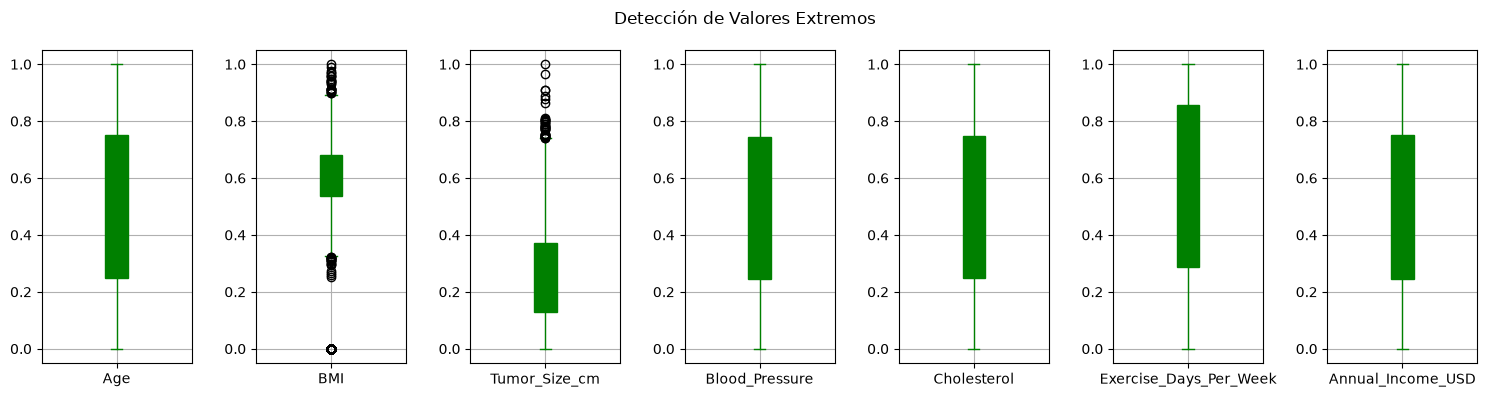

In [201]:
# Primero tomamos todas las columnas que tienen valores continuos y vemos cuales tienen outliers.
columnas_continuas = [
    'Age', 'BMI', 'Tumor_Size_cm', 'Blood_Pressure', 'Cholesterol', 
    'Exercise_Days_Per_Week', 'Annual_Income_USD']

# Creamos la figura sobre la que trabajemos
plt.figure(figsize=(15, 4))

# Ahora recorremos cada columna para que cada una tenga su gráfico
# Seleccionamos la columna
# Luego cremos su propiop gráfico
# Lo hacemos de tipo box porque permite identificarlos de mejor manera
for i in range(len(columnas_continuas)):
    col = columnas_continuas[i]
    plt.subplot(1, len(columnas_continuas), i + 1)
    df.boxplot(column=col, patch_artist=True, color='green')

plt.suptitle('Detección de Valores Extremos')
plt.tight_layout()
plt.show()

Notar que solo dos columnas tienen outliers y son BMI y Tumor_Size_cm

In [202]:
cols_outliers = ['BMI', 'Tumor_Size_cm']

for col in cols_outliers:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    
    # Recortar los valores al rango permitido
    df[col] = df[col].clip(lower=limite_inferior, upper=limite_superior)

## Árbol de desicion

In [203]:
# seleccionamos las variables predictoras y la variable dependiente
X = df.drop(columns=['Cancer'])
y = df['Cancer']

#datos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3)

In [204]:
# Definimos el modelo y especificamos sus hiperparámetros
classifier = DecisionTreeClassifier(max_depth=6)

#ajustamos a los datos de entrenamiento
classifier.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In [205]:
fig = plt.figure(figsize=(20,20))
ax = fig.add_subplot(111)
plot_tree(classifier, ax=ax)

[Text(0.5, 0.75, 'x[14] <= 0.5\ngini = 0.315\nsamples = 7000\nvalue = [5631, 1369]'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 5631\nvalue = [5631, 0]'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.0\nsamples = 1369\nvalue = [0, 1369]'),
 Text(0.625, 0.5, '  False')]

In [206]:
#predecimos las categorías para el dataset de prueba
y_pred_test = classifier.predict(X_test)

In [207]:
X_train.head()

,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,Genetic_Mutation,...,Biopsy_Result,Cancer_Stage,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Annual_Income_USD,Breastfeeding_History_No,Breastfeeding_History_Not Applicable,Breastfeeding_History_Yes
4,0.359375,1,0.648526,1,1,0.0,1.0,0.0,0,0,...,1,0,0.222222,0.800000,0,0.000000,0.562373,0,0,1
1504,0.062500,1,0.562358,0,0,0.0,0.0,0.0,0,0,...,1,0,0.400000,0.194118,0,0.714286,0.210283,1,0,0
9730,0.125000,1,0.609977,0,0,0.0,1.0,1.0,0,0,...,1,0,0.222222,0.670588,0,0.857143,0.480007,1,0,0
2396,0.562500,1,0.671202,0,0,0.0,2.0,0.0,1,0,...,1,0,0.444444,0.311765,0,1.000000,0.156051,0,0,1
8711,0.578125,1,0.535147,0,0,0.0,1.0,0.0,0,0,...,1,0,0.588889,0.147059,0,0.571429,0.035150,0,0,1


## Parte 3: Evalúen las predicciones del modelo mediante las métricas de *fairness* de Aequitas.

### **Indicaciones**

Consideren como posibles atributos demográficos sensibles del dataset: `age`, `Gender`, `BMI` y `Annual_Income_USD`.

**Paso 1: Categoricen las variables continuas.**
Aequitas requiere variables categóricas. Para atributos continuos o con muchas categorías, como `age`, creen una columna auxiliar que agrupe los valores en tramos. Por ejemplo:

- 0-30 años: joven
- 30-40 años: adulto
- 40-60 años: adulto mayor

**Paso 2: Elijan al menos 2 atributos sensibles y definan sus grupos.**
De los cuatro atributos mencionados, escojan al menos dos para el análisis. Para cada uno, definan sus categorías (agrupándolas si es necesario, como en el paso 1).

**Paso 3: Definan, dentro de cada atributo, qué grupo es privilegiado y cuál no privilegiado.**
El grupo privilegiado es aquel que ustedes consideran de referencia, es decir, contra el cual se comparará el desempeño del modelo en los demás grupos del mismo atributo. Por ejemplo, para `age` podrían definir:

| Grupo | Categoría |
|---|---|
| Privilegiado | adulto |
| No privilegiado | joven |
| No privilegiado | adulto mayor |

Y para `Annual_Income_USD`, tras agruparlo en tramos (por ejemplo, ingreso alto / ingreso bajo):

| Grupo | Categoría |
|---|---|
| Privilegiado | ingreso alto |
| No privilegiado | ingreso bajo |

La elección de qué categoría es privilegiada y cuál no queda a su criterio, pero deben justificarla.

**Paso 4: Reporten las métricas.**
Finalmente, reporten las métricas de *False Negative Rate Parity* y *False Discovery Rate Parity* para los atributos y grupos definidos.

### **RESPONDER**

Pregunta 3.1 Expliquen los resultados obtenidos.

Pregunta 3.2 ¿Cuán justas se pueden considerar las predicciones del modelo para cada grupo? ¿Cómo relacionarían esto con los contenidos del curso?

Pregunta 3.3 El dataset no contiene variables asociadas a la raza, por ejemplo. ¿Significa esto que el modelo no aprenderá sesgos respecto a ese grupo? Investiguen y justifiquen su respuesta.

In [ ]:
### codigo aquí

## Parte 4: Aplique el algoritmo EqOddsPostProcessing sobre las predicciones del modelo de la pregunta 1. Obtenga las predicciones modificadas y evalúelas.

#### Indicaciones:

- Obtenga tanto las instancias de BinaryLabelDatasetMetric como de ClassificationMetric y calcule al menos una métrica de Fairness.

### **RESPONDER**

pregunta 4.1: comentar brevemente los resultados obtenidos, y evaluar los cambios en las métricas de Fairness. Reflexionar sobre los beneficios y limitaciones


In [ ]:
### codigo aquí

## **Parte 5** (bonus +5 decimas) :  

Aplique el algoritmo de Reweighing sobre los datos de entrenamiento. Compare las métricas de Fairness para los datos de entrenamiento antes y después de aplicar Reweighing.

Luego, entrene un Arbol de decisión utilizando los datos de entrenamiento modificados y obtenga las métricas de Fairness de las predicciones de dicho modelo.

Analice cómo varió el *accuracy* del modelo respecto al original y las métricas de Fairness y reflexione sobre las implicancias sociales de estas decisiones.

### Indicaciones:
Puedes considerar los grupos priviligiados/no priviligiados mencionados en la parte 3. Considere al menos 2.

In [ ]:
### codigo aquí